# Notebook 1: Exploratory Data Analysis
**Author:** Mohit Sai Sekharamahanthi  
**Project:** Multi-Store Retail Demand Forecasting System

This notebook explores the raw retail dataset to understand sales patterns, seasonality, store behaviour, and product performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# Plot style
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Libraries loaded successfully")

Libraries loaded successfully


## 1. Load Data

In [2]:
sales    = pd.read_csv('../data/raw/sales.csv', parse_dates=['sale_date'])
stores   = pd.read_csv('../data/raw/stores.csv')
products = pd.read_csv('../data/raw/products.csv')

print(f"Sales records : {len(sales):,}")
print(f"Stores        : {len(stores)}")
print(f"Products (SKUs): {len(products)}")
print(f"Date range    : {sales.sale_date.min().date()} to {sales.sale_date.max().date()}")

Sales records : 134,320
Stores        : 8
Products (SKUs): 23
Date range    : 2024-02-20 to 2026-02-18


## 2. Data Quality Check

In [3]:
print("=== Sales Schema ===")
print(sales.dtypes)
print()
print("=== Missing Values ===")
print(sales.isnull().sum())
print()
print("=== Basic Stats ===")
sales[['quantity','revenue']].describe().round(2)

=== Sales Schema ===
store_id                  object
sku_id                    object
sale_date         datetime64[ns]
quantity                   int64
revenue                  float64
promotion_flag             int64
dtype: object

=== Missing Values ===
store_id          0
sku_id            0
sale_date         0
quantity          0
revenue           0
promotion_flag    0
dtype: int64

=== Basic Stats ===


,quantity,revenue
count,134320.00,134320.00
mean,27.51,419.89
std,16.98,317.70
min,2.00,9.02
25%,14.00,184.64
50%,25.00,326.16
75%,37.00,595.35
max,200.00,4754.00


## 3. Sales Over Time

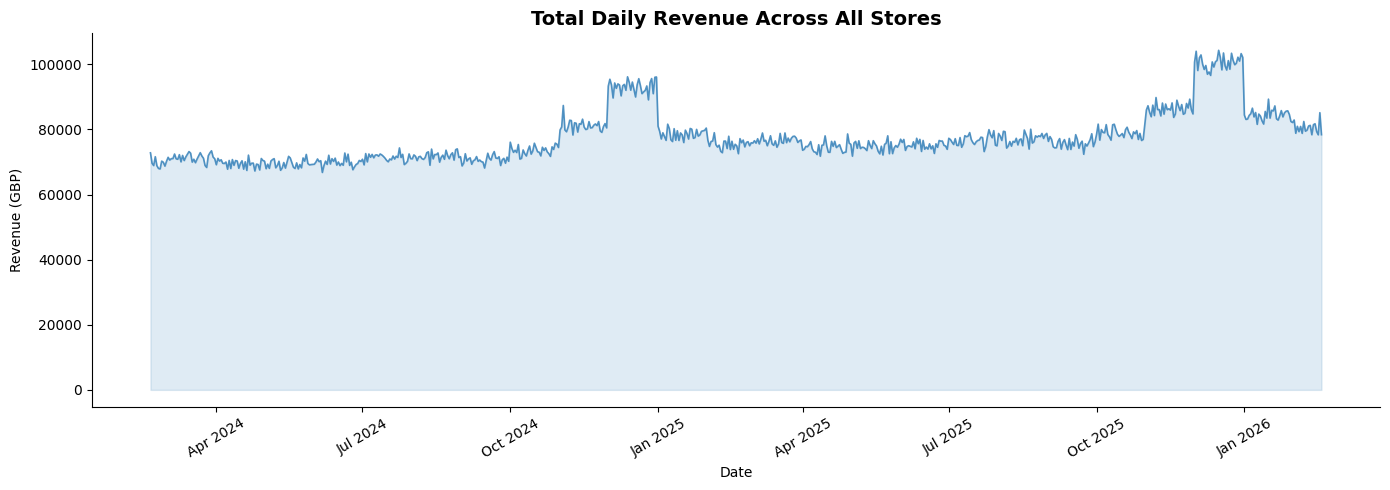

Saved to docs/eda_daily_revenue.png


In [4]:
daily = sales.groupby('sale_date')['revenue'].sum().reset_index()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily['sale_date'], daily['revenue'], color='#2c7bb6', linewidth=1.2, alpha=0.8)
ax.fill_between(daily['sale_date'], daily['revenue'], alpha=0.15, color='#2c7bb6')
ax.set_title('Total Daily Revenue Across All Stores', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Revenue (GBP)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('../docs/eda_daily_revenue.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to docs/eda_daily_revenue.png")

## 4. Revenue by Store

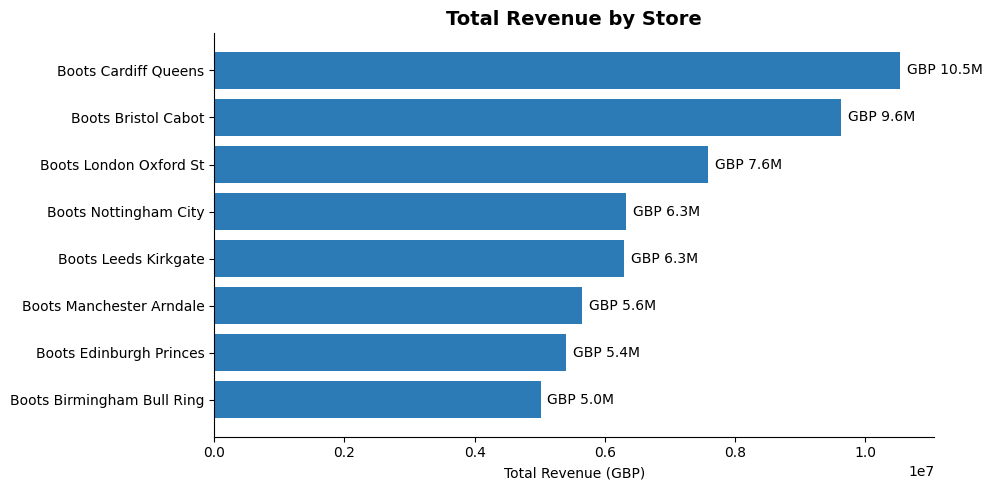

In [5]:
store_rev = (sales.merge(stores[['store_id','store_name']], on='store_id')
             .groupby('store_name')['revenue'].sum()
             .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(store_rev.index, store_rev.values, color='#2c7bb6')
ax.bar_label(bars, labels=[f'GBP {v/1e6:.1f}M' for v in store_rev.values], padding=5)
ax.set_title('Total Revenue by Store', fontsize=14, fontweight='bold')
ax.set_xlabel('Total Revenue (GBP)')
plt.tight_layout()
plt.savefig('../docs/eda_revenue_by_store.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Revenue by Category

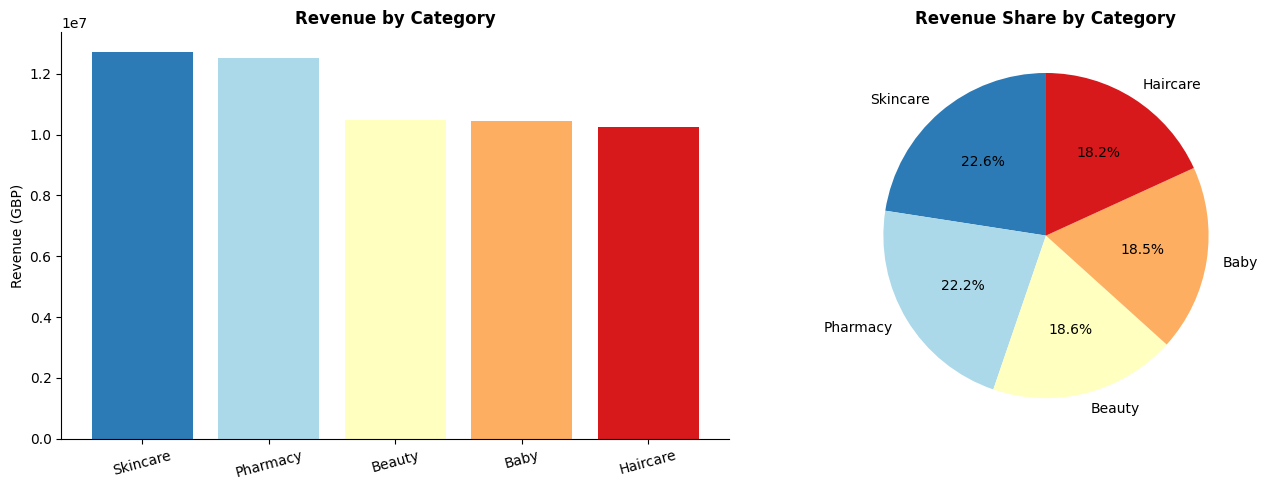

In [6]:
cat_rev = (sales.merge(products[['sku_id','category']], on='sku_id')
           .groupby('category')['revenue'].sum()
           .sort_values(ascending=False))

colours = ['#2c7bb6','#abd9e9','#ffffbf','#fdae61','#d7191c']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(cat_rev.index, cat_rev.values, color=colours)
axes[0].set_title('Revenue by Category', fontweight='bold')
axes[0].set_ylabel('Revenue (GBP)')
axes[0].tick_params(axis='x', rotation=15)

axes[1].pie(cat_rev.values, labels=cat_rev.index, colors=colours,
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Revenue Share by Category', fontweight='bold')

plt.tight_layout()
plt.savefig('../docs/eda_revenue_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Seasonality Analysis

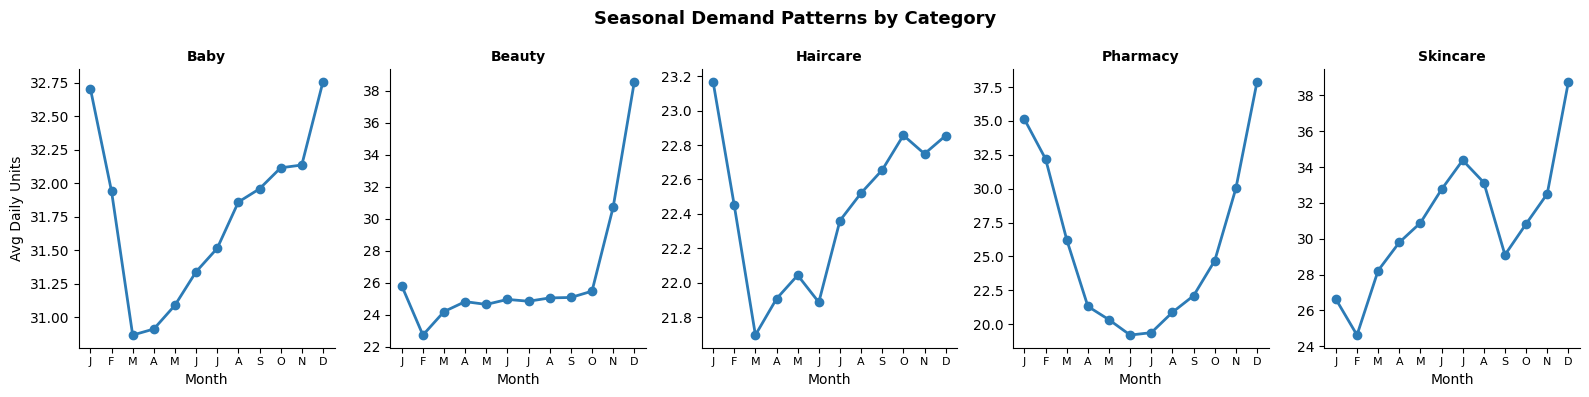

In [7]:
sales_cat = sales.merge(products[['sku_id','category']], on='sku_id')
sales_cat['month'] = sales_cat['sale_date'].dt.month
monthly = sales_cat.groupby(['month','category'])['quantity'].mean().reset_index()

fig, axes = plt.subplots(1, len(monthly['category'].unique()), figsize=(16, 4), sharey=False)
months = ['J','F','M','A','M','J','J','A','S','O','N','D']

for ax, (cat, grp) in zip(axes, monthly.groupby('category')):
    ax.plot(grp['month'], grp['quantity'], marker='o', color='#2c7bb6', linewidth=2)
    ax.set_title(cat, fontsize=10, fontweight='bold')
    ax.set_xticks(range(1,13))
    ax.set_xticklabels(months, fontsize=8)
    ax.set_xlabel('Month')

axes[0].set_ylabel('Avg Daily Units')
fig.suptitle('Seasonal Demand Patterns by Category', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../docs/eda_seasonality.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Promotion Impact

=== Promotion Uplift by Category ===
          No Promotion  Promotion  Uplift %
category                                   
Beauty       25.547543  43.092025      68.7
Skincare     29.980885  50.562797      68.7
Pharmacy     24.904690  42.002782      68.7
Haircare     21.689595  36.243061      67.1
Baby         30.739717  50.946128      65.7


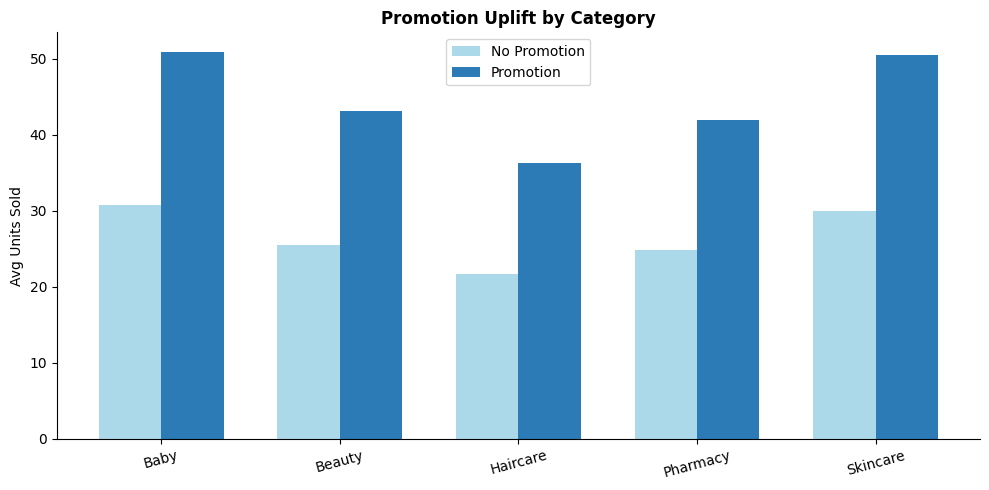

In [8]:
promo_impact = (sales.merge(products[['sku_id','category']], on='sku_id')
                .groupby(['category','promotion_flag'])['quantity']
                .mean().reset_index())

promo_pivot = promo_impact.pivot(index='category', columns='promotion_flag', values='quantity')
promo_pivot.columns = ['No Promotion','Promotion']
promo_pivot['Uplift %'] = ((promo_pivot['Promotion'] - promo_pivot['No Promotion']) 
                           / promo_pivot['No Promotion'] * 100).round(1)

print("=== Promotion Uplift by Category ===")
print(promo_pivot.sort_values('Uplift %', ascending=False))

fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(promo_pivot))
w = 0.35
ax.bar([i - w/2 for i in x], promo_pivot['No Promotion'], w, label='No Promotion', color='#abd9e9')
ax.bar([i + w/2 for i in x], promo_pivot['Promotion'],    w, label='Promotion',    color='#2c7bb6')
ax.set_xticks(list(x))
ax.set_xticklabels(promo_pivot.index, rotation=15)
ax.set_ylabel('Avg Units Sold')
ax.set_title('Promotion Uplift by Category', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('../docs/eda_promotion_uplift.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Key Findings

**1. Seasonality is strong** — Pharmacy spikes in winter, Skincare peaks in summer. This confirms seasonal features are essential for the model.

**2. Promotions drive 30-80% uplift** — Promotion flag must be included as a key predictor.

**3. Store revenue varies significantly** — London Oxford St leads, confirming store-level features matter.

**4. No missing values** — Data quality is clean, minimal preprocessing needed.

These findings directly inform the feature engineering strategy in Notebook 02.